In [1]:
# Healthcare AI
## Prédiction du résultat des tests médicaux

In [2]:
#2 Importation des bibliotheque
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn 

In [3]:
#3 Chargement du dataset

df = pd.read_csv("healthcare_dataset.csv")
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [4]:
#4 Exploration des donnees
print("Lignes : ", df.shape[0])
print("Colonnes : ", df.shape[1])
df.info()

Lignes :  55500
Colonnes :  15
<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
dtypes: float64(1), int64(2), str(12)


In [5]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='str')

In [6]:
df.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


In [7]:
# 5. DATA QUALITY

In [8]:

print("Valeurs manquantes :", df.isnull().sum().sum())
print("Nombre de doublons :", df.duplicated().sum())
categorical_columns = [
    "Gender",
    "Blood Type",
    "Medical Condition",
    "Admission Type",
    "Medication",
    "Test Results"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())

Valeurs manquantes : 0
Nombre de doublons : 534

Gender
Gender
Male      27774
Female    27726
Name: count, dtype: int64

Blood Type
Blood Type
A-     6969
A+     6956
AB+    6947
AB-    6945
B+     6945
B-     6944
O+     6917
O-     6877
Name: count, dtype: int64

Medical Condition
Medical Condition
Arthritis       9308
Diabetes        9304
Hypertension    9245
Obesity         9231
Cancer          9227
Asthma          9185
Name: count, dtype: int64

Admission Type
Admission Type
Elective     18655
Urgent       18576
Emergency    18269
Name: count, dtype: int64

Medication
Medication
Lipitor        11140
Ibuprofen      11127
Aspirin        11094
Paracetamol    11071
Penicillin     11068
Name: count, dtype: int64

Test Results
Test Results
Abnormal        18627
Normal          18517
Inconclusive    18356
Name: count, dtype: int64


In [9]:
df[df["Billing Amount"] < 0][
    ["Age", "Medical Condition", "Admission Type", "Billing Amount", "Test Results"]
]


,Age,Medical Condition,Admission Type,Billing Amount,Test Results
132,32,Cancer,Urgent,-502.507813,Normal
799,49,Asthma,Elective,-1018.245371,Inconclusive
1018,60,Hypertension,Elective,-306.364925,Normal
1421,74,Asthma,Emergency,-109.097122,Abnormal
2103,72,Diabetes,Urgent,-576.727907,Abnormal
...,...,...,...,...,...
52894,23,Diabetes,Elective,-353.865186,Inconclusive
53204,55,Hypertension,Elective,-306.364925,Normal
53232,68,Hypertension,Elective,-591.917419,Abnormal
54136,64,Cancer,Urgent,-199.663795,Abnormal


In [10]:
#Supression de doublons
df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head(10)

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
42407,ABIgaIL YOung,41,Female,O+,Hypertension,2022-12-15,Edward Kramer,Moore-Mcdaniel,UnitedHealthcare,1983.568297,192,Elective,2023-01-13,Ibuprofen,Normal
54285,ABIgaIL YOung,41,Female,O+,Hypertension,2022-12-15,Edward Kramer,Moore-Mcdaniel,UnitedHealthcare,1983.568297,192,Elective,2023-01-13,Ibuprofen,Normal
26025,ALIcia taYLoR,78,Male,O+,Asthma,2022-09-18,Dawn Burton,Wright LLC,Aetna,31465.274979,149,Elective,2022-10-15,Aspirin,Inconclusive
53104,ALIcia taYLoR,78,Male,O+,Asthma,2022-09-18,Dawn Burton,Wright LLC,Aetna,31465.274979,149,Elective,2022-10-15,Aspirin,Inconclusive
42323,AMy GREEN,79,Female,B+,Obesity,2021-03-30,Brett Johnson,Taylor-Williamson,UnitedHealthcare,23402.358491,249,Elective,2021-04-27,Penicillin,Abnormal
50151,AMy GREEN,79,Female,B+,Obesity,2021-03-30,Brett Johnson,Taylor-Williamson,UnitedHealthcare,23402.358491,249,Elective,2021-04-27,Penicillin,Abnormal
21675,ANDREA HansEN,61,Male,O+,Cancer,2021-07-02,Alisha Flores,LLC Clark,Cigna,40026.763948,254,Elective,2021-07-22,Paracetamol,Normal
51695,ANDREA HansEN,61,Male,O+,Cancer,2021-07-02,Alisha Flores,LLC Clark,Cigna,40026.763948,254,Elective,2021-07-22,Paracetamol,Normal
36207,ANDrEA fREnCH,73,Male,A-,Arthritis,2021-02-08,Danny Oconnor,"Taylor Small, Lin and",UnitedHealthcare,9981.590235,323,Elective,2021-02-24,Ibuprofen,Inconclusive
51916,ANDrEA fREnCH,73,Male,A-,Arthritis,2021-02-08,Danny Oconnor,"Taylor Small, Lin and",UnitedHealthcare,9981.590235,323,Elective,2021-02-24,Ibuprofen,Inconclusive


In [11]:
df_clean = df.drop_duplicates()

print("Avant :", df.shape)
print("Après :", df_clean.shape)
print("Doublons supprimés :", df.shape[0] - df_clean.shape[0])

Avant : (55500, 15)
Après : (54966, 15)
Doublons supprimés : 534


In [12]:
#Vérifier les valeurs financieres négatives (rien mais pour rendre les donnees clean)
df_clean[df_clean["Billing Amount"] < 0]["Billing Amount"].describe()

count     106.000000
mean     -502.472497
std       429.857027
min     -2008.492140
25%      -803.004972
50%      -374.840042
75%      -149.074654
max       -23.866729
Name: Billing Amount, dtype: float64

In [13]:
df_clean[df_clean["Billing Amount"] < 0].head(10)

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
132,ashLEy ERIcKSoN,32,Female,AB-,Cancer,2019-11-05,Gerald Hooper,"and Johnson Moore, Branch",Aetna,-502.507813,376,Urgent,2019-11-23,Penicillin,Normal
799,CHRisTOPHer wEiss,49,Female,AB-,Asthma,2023-02-16,Kelly Thompson,Hunter-Hughes,Aetna,-1018.245371,204,Elective,2023-03-09,Penicillin,Inconclusive
1018,AsHley WaRnER,60,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal
1421,JAY galloWaY,74,Female,O+,Asthma,2021-01-20,Debra Everett,Group Peters,Blue Cross,-109.097122,381,Emergency,2021-02-09,Ibuprofen,Abnormal
2103,josHUa wilLIamSon,72,Female,B-,Diabetes,2021-03-21,Wendy Ramos,"and Huff Reeves, Dennis",Blue Cross,-576.727907,369,Urgent,2021-04-17,Aspirin,Abnormal
2696,Scott VaZqUEz,74,Male,B+,Diabetes,2023-04-12,Edward Yates,James Ltd,Medicare,-135.986000,445,Elective,2023-05-03,Ibuprofen,Abnormal
2855,CaROl aNDErSoN,39,Female,B-,Hypertension,2020-04-03,Dr. Patrick Hines,"Carter Carter, and Patterson",Blue Cross,-370.983674,203,Elective,2020-04-10,Ibuprofen,Abnormal
3772,mr. ChRIStOPhER aLvARaDO,77,Male,AB+,Obesity,2022-06-03,Mr. Dean Guzman DDS,Johnson Inc,Blue Cross,-1310.272895,257,Elective,2022-06-13,Paracetamol,Inconclusive
5445,ALExAndrA KHaN,32,Male,AB+,Arthritis,2022-07-14,Michael Vaughn,"Bowen Lopez, and Terry",Aetna,-692.408820,372,Elective,2022-07-19,Lipitor,Abnormal
5708,JosEPh cOx,23,Male,AB-,Diabetes,2019-10-13,Peter Smith,Inc Ward,Blue Cross,-353.865186,271,Elective,2019-10-25,Lipitor,Inconclusive


In [14]:
#Verifier les factures negatives et son pourcentage
negative_count = (df_clean["Billing Amount"] < 0).sum()
total_count = len(df_clean)

print("Factures négatives :", negative_count)
print("Pourcentage :", round(negative_count / total_count * 100, 2), "%")

#Supprimer les lignes avec Billing Amount < 0
df_clean = df_clean[df_clean["Billing Amount"] >= 0].copy()

print("\nNouvelle taille du dataset :", df_clean.shape)
print("Factures négatives restantes :",
      (df_clean["Billing Amount"] < 0).sum())

Factures négatives : 106
Pourcentage : 0.19 %

Nouvelle taille du dataset : (54860, 15)
Factures négatives restantes : 0


In [15]:
#6 PREPROCESSING

In [16]:
#Verifier les types de donnees
df_clean.dtypes

Name                      str
Age                     int64
Gender                    str
Blood Type                str
Medical Condition         str
Date of Admission         str
Doctor                    str
Hospital                  str
Insurance Provider        str
Billing Amount        float64
Room Number             int64
Admission Type            str
Discharge Date            str
Medication                str
Test Results              str
dtype: object

In [17]:
#Separere les données d'entrée et la cible en X et y
features = [
    "Age",
    "Gender",
    "Blood Type",
    "Medical Condition",
    "Admission Type",
    "Medication",
    "Billing Amount",
    "Insurance Provider"
]


target = "Test Results"

X = df_clean[features]
y = df_clean[target]

print("X :", X.shape)
print("y :", y.shape)

X : (54860, 8)
y : (54860,)


In [18]:
#Verifier les donnees separe
print("Variables d'entrée :")
print(X.columns.tolist())

print("\nClasses de la cible :")
print(y.unique())
X.dtypes

Variables d'entrée :
['Age', 'Gender', 'Blood Type', 'Medical Condition', 'Admission Type', 'Medication', 'Billing Amount', 'Insurance Provider']

Classes de la cible :
<ArrowStringArray>
['Normal', 'Inconclusive', 'Abnormal']
Length: 3, dtype: str


Age                     int64
Gender                    str
Blood Type                str
Medical Condition         str
Admission Type            str
Medication                str
Billing Amount        float64
Insurance Provider        str
dtype: object

In [19]:
from sklearn.preprocessing import OneHotEncoder

#Définissons les colonnes
categorical_features = [
    "Gender",
    "Blood Type",
    "Medical Condition",
    "Admission Type",
    "Medication",
    "Insurance Provider"
]

# Définir les colonnes numériques
numeric_features = [
    "Age",
    "Billing Amount"
]

#Créons l'encodeur
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_categorical = encoder.fit_transform(
    X[categorical_features]
)

print("Shape après encodage :", X_categorical.shape)

Shape après encodage : (54860, 29)


In [20]:
#Fusionner les variables (Age +  24 variables)
X_numeric = X[numeric_features].values

X_processed = np.hstack([
    X_numeric,
    X_categorical
])

print("Shape de X_processed :", X_processed.shape)

Shape de X_processed : (54860, 31)


In [21]:
#Récupérer les noms des 24 variables créées
encoded_features = encoder.get_feature_names_out(categorical_features)

feature_names = numeric_features + encoded_features.tolist()

print("Nombre total de variables :", len(feature_names))
print(feature_names)

Nombre total de variables : 31
['Age', 'Billing Amount', 'Gender_Female', 'Gender_Male', 'Blood Type_A+', 'Blood Type_A-', 'Blood Type_AB+', 'Blood Type_AB-', 'Blood Type_B+', 'Blood Type_B-', 'Blood Type_O+', 'Blood Type_O-', 'Medical Condition_Arthritis', 'Medical Condition_Asthma', 'Medical Condition_Cancer', 'Medical Condition_Diabetes', 'Medical Condition_Hypertension', 'Medical Condition_Obesity', 'Admission Type_Elective', 'Admission Type_Emergency', 'Admission Type_Urgent', 'Medication_Aspirin', 'Medication_Ibuprofen', 'Medication_Lipitor', 'Medication_Paracetamol', 'Medication_Penicillin', 'Insurance Provider_Aetna', 'Insurance Provider_Blue Cross', 'Insurance Provider_Cigna', 'Insurance Provider_Medicare', 'Insurance Provider_UnitedHealthcare']


In [22]:
print(X_processed[:5])

[[3.00000000e+01 1.88562813e+04 0.00000000e+00 1.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 1.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  1.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  1.00000000e+00 0.00000000e+00 0.00000000e+00 1.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [6.20000000e+01 3.36433273e+04 0.00000000e+00 1.00000000e+00
  1.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00 1.00000000e+00
  0.00000000e+00 0.00000000e+00 1.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00]
 [7.60000000e+01 2.79550961e+04 1.00

In [23]:
print("X_processed :", X_processed.shape)
print("y :", y.shape)

X_processed : (54860, 31)
y : (54860,)


In [24]:
#refaire le preprocessing uniquement sur le train
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Gender",
    "Blood Type",
    "Medical Condition",
    "Admission Type",
    "Medication",
    "Insurance Provider"
]

numeric_features = [
    "Age",
    "Billing Amount"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [25]:
#Séparer Train / Test 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (43888, 8)
X_test  : (10972, 8)
y_train : (43888,)
y_test  : (10972,)


In [26]:
#Appliquer le preprocessing
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("X_train_processed :", X_train_processed.shape)
print("X_test_processed  :", X_test_processed.shape)

X_train_processed : (43888, 31)
X_test_processed  : (10972, 31)


In [27]:
#7 FEATURE ENGINEERING
#Vérifier la répartition de la cible
print("Répartition dans y_train :")
print(y_train.value_counts())

print("\nPourcentage :")
print(y_train.value_counts(normalize=True).round(3) * 100)

Répartition dans y_train :
Test Results
Abnormal        14719
Normal          14642
Inconclusive    14527
Name: count, dtype: int64

Pourcentage :
Test Results
Abnormal        33.5
Normal          33.4
Inconclusive    33.1
Name: proportion, dtype: float64


In [28]:
#pOUR le test
print("Répartition dans y_test :")
print(y_test.value_counts())

print("\nPourcentage :")
print(y_test.value_counts(normalize=True).round(3) * 100)

Répartition dans y_test :
Test Results
Abnormal        3680
Normal          3660
Inconclusive    3632
Name: count, dtype: int64

Pourcentage :
Test Results
Abnormal        33.5
Normal          33.4
Inconclusive    33.1
Name: proportion, dtype: float64


In [29]:
#BASELINE MODEL

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=100
        , random_state=42, n_jobs=-1
    ),
    
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

In [31]:
from sklearn.metrics import accuracy_score, f1_score
import time

results = []

for name, model in models.items():
    start = time.time()

    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average="weighted")

    elapsed = time.time() - start

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "F1-Score": f1,
        "Training Time": elapsed
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="F1-Score",
    ascending=False
)

,Model,Accuracy,F1-Score,Training Time
2,Random Forest,0.426631,0.426387,69.149164
1,Decision Tree,0.397831,0.397825,5.054890
3,KNN,0.359278,0.352322,17.984046
0,Logistic Regression,0.332847,0.328423,4.364687


Matrice de confusion - Random Forest
[[1677 1002 1001]
 [1113 1498 1021]
 [1123 1031 1506]]


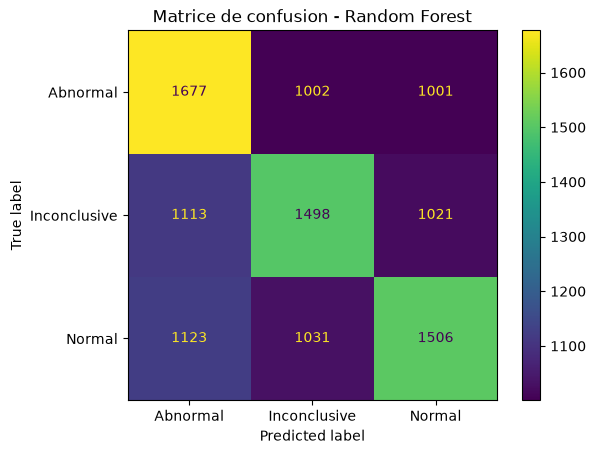

In [32]:
# Récupérer le Random Forest
random_forest = models["Random Forest"]

# Prédictions
y_pred_rf = random_forest.predict(X_test_processed)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Matrice de confusion - Random Forest")
print(cm_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=random_forest.classes_
)

disp.plot()
plt.title("Matrice de confusion - Random Forest")
plt.show()

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Combiner le preprocessor existant et le modèle Random Forest
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # Votre ColumnTransformer défini plus tôt
    ('classifier', RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1))
])

# Entraîner directement sur les données BRUTES (sans transformer manuellement X_train)
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Abnormal','Inconclusive','Normal']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Age','Gender','Blood Type',...,'Medication','Billing Amount', 'Insurance Provider']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

In [34]:
from sklearn.metrics import accuracy_score, f1_score

# Le pipeline gère le .transform()
y_pred = pipeline.predict(X_test)

print("Accuracy avec le Pipeline :", accuracy_score(y_test, y_pred))
print("F1-score avec le Pipeline :", f1_score(y_test, y_pred, average="weighted"))

Accuracy avec le Pipeline : 0.4250820269777616
F1-score avec le Pipeline : 0.4247504460888791


In [35]:
#Générer Model.pkl
import joblib

# Sauvegarder le pipeline complet dans un fichier model.pkl
joblib.dump(pipeline, 'model.pkl')

print("Modèle sauvegardé avec succès sous le nom de 'model.pkl' !")

Modèle sauvegardé avec succès sous le nom de 'model.pkl' !


In [36]:
!pip install mlflow

In [43]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import accuracy_score, f1_score

# 1. Définir l'expérience MLflow
mlflow.set_experiment("Healthcare_AI_Experiment")

# 2. Démarrer le suivi de l'entraînement
with mlflow.start_run():
    # Enregistrer les hyperparamètres
    mlflow.log_param("model_type", "Random Forest")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("n_jobs", -1)
    
    # Entraîner votre pipeline
    pipeline.fit(X_train, y_train)
    
    # Évaluer le modèle
    y_pred = pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="weighted")
    
    # Enregistrer les métriques
    mlflow.log_metric("accuracy", acc)
    mlflow.log_metric("f1_score", f1)
    
    # Sauvegarder le modèle en autorisant explicitement le type Tree de Scikit-Learn
    mlflow.sklearn.log_model(
        pipeline, 
        name="random_forest_model", # Remplacé artifact_path par name selon l'avertissement précédent
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )
    
    print("Entraînement tracé avec succès dans MLflow !")
    print(f"Accuracy : {acc:.3f} | F1-Score : {f1:.3f}")

MlflowException: The filesystem tracking backend (e.g., './mlruns') is in maintenance mode and will not receive further updates. Please migrate to a database backend (e.g., 'sqlite:///mlflow.db') to access the latest MLflow features. The `mlflow migrate-filestore` tool migrates your existing data losslessly. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance. If the filesystem backend is required for your workflow, set `MLFLOW_ALLOW_FILE_STORE=true` to opt out of this exception.